# Transformer v1: fine-tuned BERT

Multi-label clause classification over all 41 CUAD categories with `bert-base-uncased`, compared with the TF-IDF baseline on the same validation chunks.
Training is in `scripts/train_transformer.py` (2-3 hours on an M4, plugged in). It saves the model to `models/transformer_v1/` and the validation results to `results/transformer_v1/`. This notebook reads those results and retrains the baseline to score it on the same chunks.

* **Chunks:** the baseline's 512-token, 64-overlap chunks and overlap labels, split by `splits.csv`. BERT sees the first 510 tokens of each chunk.
* **Model:** `bert-base-uncased` with 41 sigmoid outputs, one per category.
* **Loss:** binary cross-entropy with positives weighted by sqrt(negatives / positives) per category.
* **Training:** 6 epochs, AdamW with 10% warmup, batch size 8. Learning rate 3e-5 for the pretrained encoder and 1e-3 for the new classification layer. Each epoch uses every train chunk with a clause plus a fresh random quarter of the empty ones. The epoch with the best validation macro average precision is kept.
* **Thresholds:** per category, chosen on validation, as in the baseline.
* **Test set:** not used.

Run 1 (`results/transformer_v1_run1/`) used one learning rate of 2e-5, all train chunks and 4 epochs. It is kept for comparison in section 4.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path("../scripts").resolve()))
import baseline_tfidf as b
from train_transformer import RESULTS_DIR, all_categories

pd.set_option("display.precision", 3)
categories = all_categories()
config = json.loads((RESULTS_DIR / "config.json").read_text())
log = pd.read_csv(RESULTS_DIR / "training_log.csv")
summary = pd.read_csv(RESULTS_DIR / "val_metrics_summary.csv", index_col=0)
chunk_metrics = pd.read_csv(RESULTS_DIR / "val_metrics_chunk_level.csv", index_col=0)
contract_metrics = pd.read_csv(RESULTS_DIR / "val_metrics_contract_level.csv", index_col=0)
print(f"best epoch {config['best_epoch']} of {config['epochs']}, trained on {config['device']}")

best epoch 6 of 6, trained on mps


## 1. Training

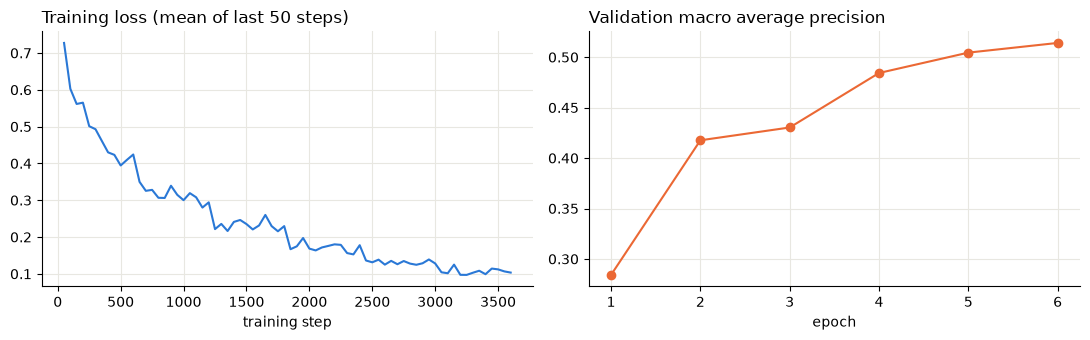

,train_loss,val_macro_avg_precision
epoch,,
1,0.499,0.284
2,0.314,0.418
3,0.232,0.430
4,0.172,0.484
5,0.131,0.504
6,0.106,0.514


In [2]:
steps = log[log["val_macro_avg_precision"].isna()]
epochs = log[log["val_macro_avg_precision"].notna()]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(steps["step"], steps["train_loss"], color="#2a78d6")
ax1.set_xlabel("training step")
ax1.set_title("Training loss (mean of last 50 steps)", loc="left")
ax2.plot(epochs["epoch"], epochs["val_macro_avg_precision"], marker="o", color="#eb6834")
ax2.set_xticks(epochs["epoch"])
ax2.set_xlabel("epoch")
ax2.set_title("Validation macro average precision", loc="left")
for ax in (ax1, ax2):
    ax.grid(color="#e8e7e1")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()
epochs[["epoch", "train_loss", "val_macro_avg_precision"]].set_index("epoch")

## 2. Validation results

In [3]:
summary

,chunk_level,contract_level
macro_precision,0.569,0.677
macro_recall,0.578,0.789
macro_f1,0.550,0.706
macro_avg_precision,0.514,0.715
micro_precision,0.642,0.786
micro_recall,0.679,0.864
micro_f1,0.660,0.823


## 3. Compared with the baseline

The baseline is retrained exactly as in `baseline_tfidf.py` and scored on the same validation chunks, with its thresholds also chosen on validation. Takes about 2 minutes.

In [4]:
base = b.run_baseline(categories, verbose=False)
val = base.chunks[base.chunks["split"] == "val"].reset_index(drop=True)
P_base = b.predict_proba(base.models, base.vectorizer.transform(val["text"]), categories)
annotations = b.load_annotations()
Y_val = b.label_chunks(val, annotations, categories)
base_chunk = b.per_category_metrics(Y_val, P_base, base.thresholds)

contract_scores = P_base.groupby(val["contract_id"]).max()
Yc = b.contract_labels(annotations, contract_scores.index, categories)
base_contract = b.per_category_metrics(Yc, pd.DataFrame(contract_scores.to_numpy(), columns=categories),
                                       base.thresholds)
base_summary = pd.DataFrame({"chunk_level": b.summarise(base_chunk),
                             "contract_level": b.summarise(base_contract)})

comparison = pd.concat({"baseline": base_summary, "transformer": summary}, axis=1)
comparison

baseline                transformer               
                    chunk_level contract_level chunk_level contract_level
macro_precision           0.617          0.728       0.569          0.677
macro_recall              0.595          0.749       0.578          0.789
macro_f1                  0.572          0.708       0.550          0.706
macro_avg_precision       0.551          0.750       0.514          0.715
micro_precision           0.626          0.802       0.642          0.786
micro_recall              0.655          0.820       0.679          0.864
micro_f1                  0.640          0.811       0.660          0.823

In [5]:
cols = ["precision", "recall", "f1", "avg_precision"]
per_cat = pd.concat({"baseline": base_chunk[cols], "transformer": chunk_metrics[cols]}, axis=1)
per_cat.insert(0, "positives", chunk_metrics["positives"])
per_cat[("change", "avg_precision")] = per_cat[("transformer", "avg_precision")] - per_cat[("baseline", "avg_precision")]
per_cat[("change", "f1")] = per_cat[("transformer", "f1")] - per_cat[("baseline", "f1")]
per_cat.round(4).to_csv(RESULTS_DIR / "val_comparison_chunk_level.csv")
per_cat.sort_values(("change", "avg_precision"))

positives  baseline                \
                                             precision recall     f1   
category                                                               
Affiliate License-Licensee                17     0.467  0.824  0.596   
Non-Disparagement                         13     0.312  0.769  0.444   
Most Favored Nation                       11     0.500  0.273  0.353   
Joint IP Ownership                        15     0.346  0.600  0.439   
Uncapped Liability                        30     0.704  0.633  0.667   
Volume Restriction                        28     0.556  0.357  0.435   
Source Code Escrow                         5     0.600  0.600  0.600   
Exclusivity                               53     0.471  0.604  0.529   
Termination for Convenience               46     0.492  0.652  0.561   
IP Ownership Assignment                   46     0.702  0.717  0.710   
Non-Transferable License                  48     0.623  0.688  0.653   
Covenant Not to Sue                       28     0.690  0.714  0.702   
Audit Rights                              86     0.814  0.814  0.814   
Minimum Commitment                        55     0.560  0.509  0.533   
Notice Period to Terminate Renewal        25     0.667  0.720  0.692   
Affiliate License-Licensor                 9     0.500  0.222  0.308   
No-Solicit of Employees                   16     0.923  0.750  0.828   
Irrevocable or Perpetual License          26     0.457  0.615  0.525   
Rofr/Rofo/Rofn                            32     0.609  0.438  0.509   
Competitive Restriction Exception         22     1.000  0.227  0.370   
Cap on Liability                         101     0.928  0.634  0.753   
Governing Law                             89     0.920  0.899  0.909   
Liquidated Damages                        25     0.846  0.440  0.579   
Expiration Date                           91     0.817  0.736  0.775   
Change of Control                         42     0.789  0.357  0.492   
Revenue/Profit Sharing                    39     0.600  0.538  0.568   
Effective Date                            83     0.562  0.711  0.628   
Insurance                                 48     0.878  0.750  0.809   
Warranty Duration                         30     0.567  0.567  0.567   
License Grant                            124     0.764  0.758  0.761   
Parties                                  110     0.843  0.782  0.811   
Price Restrictions                         3     0.018  1.000  0.035   
No-Solicit of Customers                    6     0.333  0.333  0.333   
Non-Compete                               32     0.480  0.375  0.421   
Unlimited/All-You-Can-Eat-License          5     0.125  0.200  0.154   
Anti-Assignment                          112     0.953  0.732  0.828   
Agreement Date                            78     0.864  0.731  0.792   
Post-Termination Services                 84     0.395  0.405  0.400   
Renewal Term                              43     0.727  0.744  0.736   
Document Name                             87     0.824  0.644  0.723   
Third Party Beneficiary                    6     0.069  0.333  0.114   

                                                 transformer                \
                                   avg_precision   precision recall     f1   
category                                                                     
Affiliate License-Licensee                 0.560       0.250  0.588  0.351   
Non-Disparagement                          0.375       0.400  0.154  0.222   
Most Favored Nation                        0.305       0.250  0.273  0.261   
Joint IP Ownership                         0.444       0.500  0.267  0.348   
Uncapped Liability                         0.635       0.475  0.633  0.543   
Volume Restriction                         0.401       0.357  0.357  0.357   
Source Code Escrow                         0.570       1.000  0.400  0.571   
Exclusivity                                0.478       0.351  0.509  0.415   
Terminat

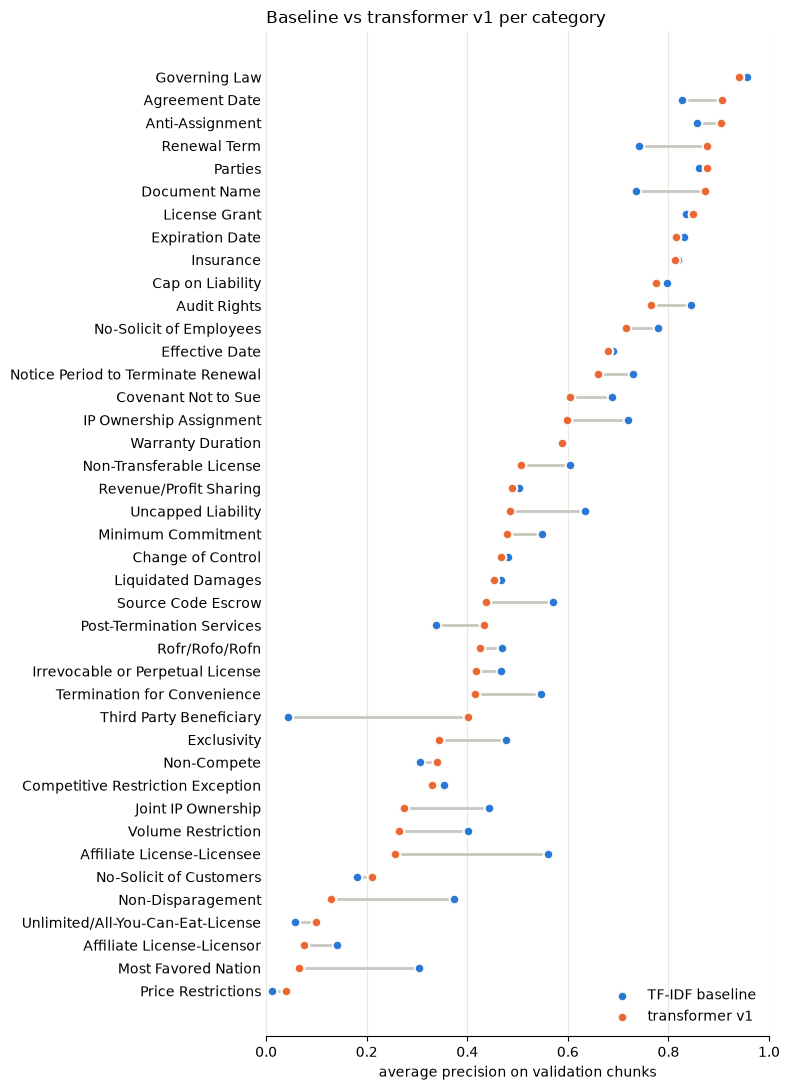

In [6]:
# Validation average precision per category, sorted by the transformer's score
order = per_cat[("transformer", "avg_precision")].sort_values().index
y = range(len(order))
base_ap = per_cat.loc[order, ("baseline", "avg_precision")]
bert_ap = per_cat.loc[order, ("transformer", "avg_precision")]

fig, ax = plt.subplots(figsize=(8, 11))
ax.hlines(y, base_ap, bert_ap, color="#c8c7c0", linewidth=2, zorder=1)
ax.scatter(base_ap, y, s=48, color="#2a78d6", label="TF-IDF baseline", zorder=2, edgecolors="#fcfcfb", linewidths=1.5)
ax.scatter(bert_ap, y, s=48, color="#eb6834", label="transformer v1", zorder=2, edgecolors="#fcfcfb", linewidths=1.5)
ax.set_yticks(list(y), order)
ax.set_xlim(0, 1)
ax.set_xlabel("average precision on validation chunks")
ax.set_title("Baseline vs transformer v1 per category", loc="left")
ax.grid(axis="x", color="#e8e7e1")
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

## 4. Run 1 vs run 2

Run 1 trained every layer at 2e-5 on all train chunks for 4 epochs. Its scores on the same validation chunks:

In [7]:
run1_dir = RESULTS_DIR.with_name("transformer_v1_run1")
run1_summary = pd.read_csv(run1_dir / "val_metrics_summary.csv", index_col=0)
run1_chunk = pd.read_csv(run1_dir / "val_metrics_chunk_level.csv", index_col=0)
runs = pd.DataFrame({
    "baseline": base_summary["chunk_level"],
    "run 1": run1_summary["chunk_level"],
    "run 2": summary["chunk_level"],
})
runs

,baseline,run 1,run 2
macro_precision,0.617,0.468,0.569
macro_recall,0.595,0.529,0.578
macro_f1,0.572,0.466,0.550
macro_avg_precision,0.551,0.415,0.514
micro_precision,0.626,0.485,0.642
micro_recall,0.655,0.626,0.679
micro_f1,0.640,0.547,0.660


In [8]:
# Mean validation average precision by how many train chunks hold the category
train_chunks = base.chunks[base.chunks["split"] == "train"].reset_index(drop=True)
train_pos = b.label_chunks(train_chunks, annotations, categories).sum()
bands = pd.cut(train_pos, [0, 50, 150, 10**6], right=False, labels=["under 50", "50-150", "150+"])
ap = pd.DataFrame({"baseline": base_chunk["avg_precision"], "run 1": run1_chunk["avg_precision"],
                   "run 2": chunk_metrics["avg_precision"]})
ap.groupby(bands, observed=True).mean().assign(categories=bands.value_counts())

,baseline,run 1,run 2,categories
under 50,0.211,0.046,0.182,8
50-150,0.557,0.364,0.487,14
150+,0.689,0.608,0.674,19


## Findings

**Headline (validation, 41 categories):** chunk macro average precision **0.514** and macro F1 **0.550**, against the baseline's 0.551 and 0.572. Micro F1 is higher than the baseline's at chunk level (0.660 vs 0.640) and contract level (0.823 vs 0.811).

1. **Close to the baseline, not yet past it.** The transformer is ahead on micro averages, which weight common categories, and behind on macro averages, which weight every category equally. It beats the baseline's average precision in 12 of 41 categories and its F1 in 17.
2. **Common categories are nearly tied.** For the 19 categories with 150+ train chunks, mean average precision is 0.674 vs 0.689. The biggest gains are *Third Party Beneficiary* (+0.36), *Document Name* and *Renewal Term* (+0.14) and *Post-Termination Services* (+0.10).
3. **Rare categories are still the weak spot.** Categories with fewer than 50 train chunks average 0.18 vs 0.21. *Affiliate License-Licensee* (-0.30), *Non-Disparagement* and *Most Favored Nation* (about -0.24) lose the most.
4. **The training setup mattered most.** Run 1 (2e-5 for every layer, all chunks, 4 epochs) reached 0.415. A faster classification layer, fewer empty chunks per epoch and 6 epochs raised it to 0.514, mostly in rare and mid-frequency categories (0.05 to 0.18, and 0.36 to 0.49).
5. **It finds more clauses per contract.** Contract-level macro recall is 0.79 vs 0.75, at lower precision (0.68 vs 0.73).
6. **It had not finished improving.** Validation average precision was still rising at epoch 6 (0.5045 to 0.5141).

**Next steps (v2):** more epochs; a contract-language encoder such as `nlpaueb/legal-bert-base-uncased`; stronger weighting or oversampling for rare categories. Train plugged in or on a GPU such as Colab, since run 2 paused for hours while the laptop slept on low battery.

**Caveat:** validation chose both the best epoch and the thresholds, so validation F1 is slightly optimistic for both models. The test set has not been used.